# Lab 4 · U-Net for medical image segmentation

**Course lab:** `CV-Week3-Lecture4.ipynb` (in `course-files/labs/`)
**Theory partner:** [notes/05_segmentation_fcn_unet_mask_rcnn.md](../notes/05_segmentation_fcn_unet_mask_rcnn.md) and [notebooks/05_segmentation_fcn_unet_mask_rcnn.ipynb](../notebooks/05_segmentation_fcn_unet_mask_rcnn.ipynb)

| Course cell | What it does | What you will see here |
|---|---|---|
| Setup: `MedicalDataset` loader | pairs each image with its mask from two folders | the loader running on **real microscopy data** (the dataset from the original U-Net paper), plus the mask-resizing bug |
| Exercise: "U-Net" | trains a small network with `BCEWithLogitsLoss` | the course's model trained properly **and** a real U-Net with skip connections, compared on held-out images (Dice, IoU, boundary sharpness) |
| Mini project: tumour segmentation | shows image / true mask / predicted mask | a tumour-segmentation prototype on a **synthetic** MRI-like dataset (clearly fake data, real method), with Dice and tumour-area estimates |

**What you will learn:** how a segmentation dataset is organised, why masks need special handling, what `BCEWithLogitsLoss`, `sigmoid > 0.5`, `ConvTranspose2d(stride=2)`, Dice and IoU mean, and **why the course's model is not really a U-Net**.

**Run time:** about 5–6 minutes on a laptop CPU (three small networks are trained). On a Colab GPU: about 1 minute.

## 0 · Theory in 60 seconds (details in notes chapter 05)

- **Semantic segmentation** = a class for **every pixel**. Output = a mask the same size as the image.
- **FCN**: replace the fully connected layers of a classifier with convolutions, so the output is a (coarse) map, then upsample it.
- **U-Net**: an **encoder** (conv + pool, repeated) shrinks the image and learns *what* is there; a **decoder** (upsample + conv, repeated) grows it back to full size; **skip connections** copy each encoder feature map across and **concatenate** it with the decoder map of the same size, so fine detail (*where exactly*) is not lost. Drawn, it looks like a "U".
- **`ConvTranspose2d(in, out, kernel_size=2, stride=2)`**: a learned upsampling that doubles height and width (each input pixel "paints" a 2×2 patch with learned weights).
- **Loss**: `BCEWithLogitsLoss` = sigmoid + binary cross-entropy in one numerically safe step. The network outputs **logits** (any real number); `sigmoid(logit)` gives a probability 0–1; **`> 0.5`** turns it into a yes/no mask.
- **Metrics**: **IoU** = |pred ∩ true| / |pred ∪ true|; **Dice** = 2|pred ∩ true| / (|pred| + |true|). Both 0 (no overlap) to 1 (perfect). Dice is always ≥ IoU (Dice = 2·IoU / (1 + IoU)).

### The dataset

The course leaves the dataset as a placeholder (`./medical/train/images`). We use the **ISBI 2012 electron-microscopy (EM) segmentation challenge** data, the very dataset the original U-Net paper (Ronneberger et al., 2015) won with: 30 grey-scale 512×512 slices of a fruit-fly nerve cord with hand-drawn masks of the **cell membranes**. It is small (about 8 MB), real and medical-research grade. We download it from the copy in the public `zhixuhao/unet` GitHub repository and arrange it in **exactly the folder layout the course's loader expects**, holding out the last 6 slices as a test set the model never trains on.

In [1]:
%matplotlib inline
import os, time, random, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(2)                     # share the CPU politely; raise on your own machine
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

DATA = "data"
root = os.path.join(DATA, "medical")
BASE = "https://raw.githubusercontent.com/zhixuhao/unet/master/data/membrane/train"
N_TEST = 6                                   # slices 24..29 are held out
for i in range(30):
    split = "test" if i >= 30 - N_TEST else "train"
    for kind, sub in (("image", "images"), ("label", "masks")):
        dest = os.path.join(root, split, sub, f"{i:02d}.png")
        if not os.path.exists(dest):
            os.makedirs(os.path.dirname(dest), exist_ok=True)
            urllib.request.urlretrieve(f"{BASE}/{kind}/{i}.png", dest + ".tmp")
            im = Image.open(dest + ".tmp")
            if kind == "label":                  # original: white = cell inside, black = membrane.
                im = Image.eval(im.convert("L"), lambda v: 255 - v)   # we segment the MEMBRANE, so make it white (= 1)
            im.save(dest); os.remove(dest + ".tmp")
for split in ("train", "test"):
    print(split, {sub: len(os.listdir(os.path.join(root, split, sub))) for sub in ("images", "masks")})

torch 2.14.1+cu130 | device: cpu


train {'images': 24, 'masks': 24}
test {'images': 6, 'masks': 6}


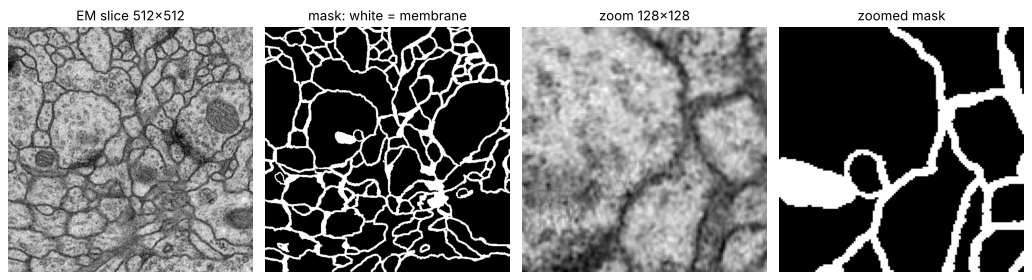

membrane pixels: 21.9% of the slice; pixel values in the mask: [  0 255]


In [2]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.4), dpi=80)
img0 = Image.open(os.path.join(root, "train", "images", "00.png")); m0 = Image.open(os.path.join(root, "train", "masks", "00.png"))
ax[0].imshow(img0, cmap="gray"); ax[0].set_title("EM slice 512x512")
ax[1].imshow(m0, cmap="gray"); ax[1].set_title("mask: white = membrane")
ax[2].imshow(np.array(img0)[150:278, 150:278], cmap="gray"); ax[2].set_title("zoom 128x128")
ax[3].imshow(np.array(m0)[150:278, 150:278], cmap="gray"); ax[3].set_title("zoomed mask")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(f"membrane pixels: {(np.array(m0) > 127).mean():.1%} of the slice; pixel values in the mask: {np.unique(np.array(m0))}")

The task: draw every cell wall. It is hard because the walls are thin (a few pixels), sometimes faint, and the inside of cells contains dark blobs (mitochondria, vesicles) that look like membrane but are not.

## 1 · Setup: the course's `MedicalDataset` loader

```python
class MedicalDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.images = os.listdir(image_dir)            # file names; the mask has the SAME name in mask_dir
    def __getitem__(self, idx):
        image = Image.open(img_path).convert("RGB")    # 3 channels
        mask  = Image.open(mask_path).convert("L")     # 1 channel, 0..255
        if self.transform:
            image = self.transform(image)
            mask  = self.transform(mask)               # <- the SAME transform for the mask
        return image, mask
```

`Dataset` needs only `__len__` (how many samples) and `__getitem__` (return sample number `idx`); `DataLoader` then shuffles and batches. `ToTensor()` turns a PIL image (H×W×C, 0–255) into a float tensor (C×H×W, 0–1). Let's run it exactly as written and look at the mask values it produces.

In [3]:
# The course's dataset class, unchanged
class MedicalDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.images = os.listdir(image_dir)
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.images[idx])
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")
        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)
        return image, mask

transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

train_dataset = MedicalDataset(os.path.join(root, "train", "images"), os.path.join(root, "train", "masks"), transform=transform)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
print("Loaded medical dataset with", len(train_dataset), "images")

images, masks = next(iter(train_loader))
print("images:", tuple(images.shape), "masks:", tuple(masks.shape))
u = torch.unique(masks)
print(f"mask contains {len(u)} different values, e.g. {[round(v, 3) for v in u[1:6].tolist()]} ...")
print(f"pixels that are neither 0 nor 1: {((masks > 0) & (masks < 1)).float().mean():.1%}")

Loaded medical dataset with 24 images
images: (4, 3, 128, 128) masks: (4, 1, 128, 128)
mask contains 256 different values, e.g. [0.004, 0.008, 0.012, 0.016, 0.02] ...
pixels that are neither 0 nor 1: 40.0%


**Bug: the mask is no longer a mask.** `Resize` uses **bilinear interpolation** by default, which averages neighbouring pixels. That is right for a photo but wrong for a label map: on every membrane edge the mask now holds in-between values like 0.3 or 0.7 ("30 % membrane"?). With `BCEWithLogitsLoss` this quietly becomes a soft target and blurs what the network learns; with a multi-class mask (0 = background, 1 = liver, 2 = tumour) averaging would invent wrong classes (1.5?).

**Fix:** give the mask its own transform with **nearest-neighbour** resizing (it only copies existing values), then threshold to make it exactly 0/1. Two more improvements:
- **`sorted(os.listdir(...))`**: `os.listdir` returns files in an arbitrary order; sorting makes runs reproducible.
- **Augmentation applied to image and mask together**: with only 24 training slices, random flips and 90° rotations are almost free extra data, but they must be the *same* random flip for both, so they live inside `__getitem__`, not in two independent `transforms` pipelines.

In [4]:
class MedicalDataset(Dataset):
    """Fixed version: separate mask transform (nearest + binarise) and joint augmentation."""
    def __init__(self, image_dir, mask_dir, size=128, augment=False):
        self.image_dir, self.mask_dir, self.augment = image_dir, mask_dir, augment
        self.images = sorted(os.listdir(image_dir))                                        # FIX: fixed order
        self.img_tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
        self.mask_tf = transforms.Compose([transforms.Resize((size, size), interpolation=transforms.InterpolationMode.NEAREST),
                                           transforms.ToTensor()])                          # FIX: nearest for labels
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        name = self.images[idx]
        image = self.img_tf(Image.open(os.path.join(self.image_dir, name)).convert("RGB"))
        mask = (self.mask_tf(Image.open(os.path.join(self.mask_dir, name)).convert("L")) > 0.5).float()   # FIX: exactly 0/1
        if self.augment:                                                                    # same random flip/rotation for both
            if random.random() < 0.5:
                image, mask = image.flip(-1), mask.flip(-1)
            if random.random() < 0.5:
                image, mask = image.flip(-2), mask.flip(-2)
            k = random.randint(0, 3)
            image, mask = torch.rot90(image, k, (1, 2)), torch.rot90(mask, k, (1, 2))
        return image, mask

train_dataset = MedicalDataset(os.path.join(root, "train", "images"), os.path.join(root, "train", "masks"), augment=True)
test_dataset = MedicalDataset(os.path.join(root, "test", "images"), os.path.join(root, "test", "masks"))   # FIX: a held-out split
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=6, shuffle=False)

images, masks = next(iter(train_loader))
print("train:", len(train_dataset), "slices | test:", len(test_dataset), "slices (never used for training)")
print("mask values now:", torch.unique(masks).tolist(), "| membrane fraction at 128x128:", f"{masks.mean():.1%}")

train: 24 slices | test: 6 slices (never used for training)
mask values now: [0.0, 1.0] | membrane fraction at 128x128: 22.5%


## 2 · Exercise: the course's "U-Net"

```python
self.encoder = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))           # 3x128x128 -> 64x64x64
self.decoder = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ReLU(), nn.Conv2d(32, 1, 1))  # -> 32x128x128 -> 1x128x128
```

Line by line:
- `Conv2d(3, 64, 3, padding=1)`: 64 learned 3×3 filters over the RGB input; `padding=1` keeps 128×128.
- `MaxPool2d(2)`: halves the size to 64×64 (keeps the strongest response in each 2×2 block).
- `ConvTranspose2d(64, 32, 2, stride=2)`: learned upsampling back to 128×128.
- `Conv2d(32, 1, 1)`: a 1×1 convolution that mixes the 32 channels into **one logit per pixel**.

**This is not a U-Net.** It has **one** level down and one up, so every output pixel sees only a 4×4-pixel neighbourhood of the input (too little context to tell a membrane from a dark blob inside a cell), and it has **no skip connections**: nothing is concatenated from encoder to decoder. It is a tiny encoder–decoder (closer to a shallow FCN). We'll keep it as the course wrote it, train it properly, and compare it with:

1. **`DeepNoSkip`**: a 4-level encoder–decoder, same depth as our U-Net but *without* skip connections, to separate the effect of **depth** from the effect of **skips**.
2. **`UNet`**: a real (small) U-Net: 4 levels (3 poolings), two 3×3 convs + BatchNorm + ReLU per level, `ConvTranspose2d(stride=2)` up, and the encoder features **concatenated** in at every level.

In [5]:
# The course's model, unchanged except for the class name
class CourseUNet(nn.Module):
    def __init__(self):
        super(CourseUNet, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),
            nn.Conv2d(32, 1, 1)
        )
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

def double_conv(cin, cout):
    """Two 3x3 conv + BatchNorm + ReLU: the basic U-Net block."""
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    """A real U-Net: encoder, bottleneck, decoder, and skip connections (concatenation) at every level."""
    def __init__(self, in_ch=3, out_ch=1, base=8, skips=True):
        super().__init__()
        self.skips = skips
        c = [base, base * 2, base * 4, base * 8]                    # 8, 16, 32, 64 channels (kept small for a CPU)
        self.down = nn.ModuleList([double_conv(in_ch, c[0]), double_conv(c[0], c[1]), double_conv(c[1], c[2])])
        self.bottleneck = double_conv(c[2], c[3])                  # 16x16 at 128x128 input: wide context
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[3], c[2], 2, stride=2),
                                 nn.ConvTranspose2d(c[2], c[1], 2, stride=2),
                                 nn.ConvTranspose2d(c[1], c[0], 2, stride=2)])
        k = 2 if skips else 1                                       # concatenation doubles the channels
        self.dec = nn.ModuleList([double_conv(c[2] * k, c[2]), double_conv(c[1] * k, c[1]), double_conv(c[0] * k, c[0])])
        self.head = nn.Conv2d(c[0], out_ch, 1)                      # 1x1 conv -> one logit per pixel
    def forward(self, x):
        saved = []
        for block in self.down:                                     # encoder: conv, remember, pool
            x = block(x); saved.append(x); x = F.max_pool2d(x, 2)
        x = self.bottleneck(x)
        for up, dec, s in zip(self.up, self.dec, reversed(saved)):  # decoder: upsample, (concat skip), conv
            x = up(x)
            if self.skips:
                x = torch.cat([s, x], dim=1)                        # <- THE skip connection
            x = dec(x)
        return self.head(x)

for name, m in [("CourseUNet", CourseUNet()), ("DeepNoSkip", UNet(skips=False)), ("UNet", UNet())]:
    out = m(torch.zeros(1, 3, 128, 128))
    print(f"{name:11s} {sum(p.numel() for p in m.parameters()):>9,} parameters | output {tuple(out.shape)}")

CourseUNet     10,049 parameters | output (1, 1, 128, 128)
DeepNoSkip    109,433 parameters | output (1, 1, 128, 128)
UNet          121,529 parameters | output (1, 1, 128, 128)


### Training (the course's loop, plus evaluation on the held-out slices)

The course's loop is correct as a loop: `zero_grad → forward → loss → backward → step`. What it lacks is (a) more than 2 epochs (24 images × 2 epochs = 12 weight updates, nowhere near enough), (b) any measurement on data the model has not seen, and (c) `model.eval()` + `torch.no_grad()` when predicting (BatchNorm must use its stored statistics at test time).

We train all three models with the same loss (`BCEWithLogitsLoss`), optimiser (Adam, lr = 0.001), augmentation and number of epochs, and after every epoch compute **Dice on the 6 test slices**.

In [6]:
def dice_iou(logits, target, thr=0.5):
    pred = (torch.sigmoid(logits) > thr).float()                   # probability > 0.5  ->  membrane
    inter = (pred * target).sum().item(); p, t = pred.sum().item(), target.sum().item()
    return 2 * inter / (p + t + 1e-8), inter / (p + t - inter + 1e-8)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                                                   # FIX: inference mode (BatchNorm uses running stats)
    logits, targets = [], []
    for images, masks in loader:
        logits.append(model(images.to(device)).cpu()); targets.append(masks)
    logits, targets = torch.cat(logits), torch.cat(targets)
    return (*dice_iou(logits, targets), logits, targets)

def train(model, epochs, lr=0.001):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"loss": [], "dice": []}
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        hist["loss"].append(running_loss / len(train_loader))
        hist["dice"].append(evaluate(model, test_loader)[0])
        if epoch in (1, 2) or epoch % 10 == 0:
            print(f"  Epoch {epoch:3d}, Loss: {hist['loss'][-1]:.4f}, test Dice: {hist['dice'][-1]:.3f}")
    return hist

EPOCHS = 40
models, hists, times = {}, {}, {}
for name, make in [("CourseUNet", CourseUNet), ("DeepNoSkip", lambda: UNet(skips=False)), ("UNet", UNet)]:
    torch.manual_seed(0); random.seed(0)
    print(name)
    t = time.time()
    models[name] = make()
    hists[name] = train(models[name], EPOCHS)
    times[name] = time.time() - t
    print(f"  trained in {times[name]:.0f} s")

CourseUNet


  Epoch   1, Loss: 0.6688, test Dice: 0.000


  Epoch   2, Loss: 0.6406, test Dice: 0.000


  Epoch  10, Loss: 0.5042, test Dice: 0.000


  Epoch  20, Loss: 0.4904, test Dice: 0.000


...

  Epoch   2, Loss: 0.6499, test Dice: 0.000


  Epoch  10, Loss: 0.4922, test Dice: 0.707


  Epoch  20, Loss: 0.4104, test Dice: 0.735


  Epoch  30, Loss: 0.3514, test Dice: 0.740


  Epoch  40, Loss: 0.3089, test Dice: 0.736
  trained in 26 s


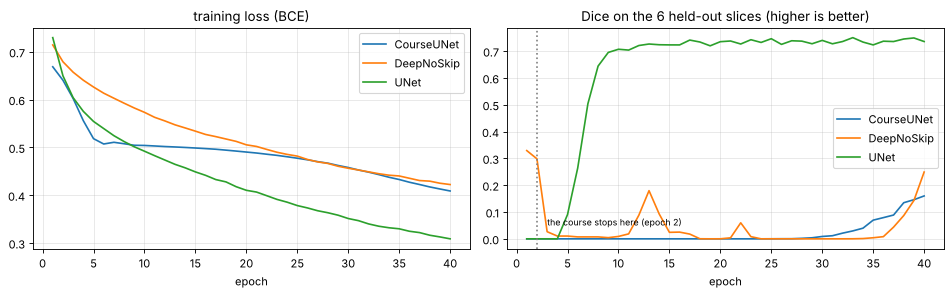

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), dpi=80)
for name, h in hists.items():
    ax[0].plot(range(1, EPOCHS + 1), h["loss"], label=name)
    ax[1].plot(range(1, EPOCHS + 1), h["dice"], label=name)
ax[0].set_title("training loss (BCE)"); ax[1].set_title("Dice on the 6 held-out slices (higher is better)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
ax[1].axvline(2, color="grey", ls=":"); ax[1].text(3, 0.05, "the course stops here (epoch 2)", fontsize=8)
plt.tight_layout(); plt.show()

### Held-out comparison: Dice, IoU and boundary sharpness

Four measurements on the 6 test slices:
- **Dice and IoU at the standard threshold 0.5.**
- **Best-threshold Dice**: a model can draw the right structure but be *under-confident* (membrane probabilities around 0.3, never above 0.5). Trying thresholds 0.05–0.95 and keeping the best separates "wrong shape" from "wrong confidence". (Choosing the threshold on the test set flatters every model a little; in a real project you'd choose it on a separate validation set.)
- **Boundary F1** (at that best threshold): take the outline pixels of the predicted mask and of the true mask; precision = share of predicted outline pixels within 1 pixel of a true outline, recall = the reverse, F1 = their harmonic mean. **Blurry, smeared predictions score low** even when they cover roughly the right area: this is our "boundary sharpness" number.
- **Contrast**: mean predicted probability on true membrane pixels minus mean on the other pixels (1 = perfect separation, 0 = can't tell them apart).

For reference, a "model" that marks **every** pixel as membrane would get Dice ≈ 2·f/(1+f), where f is the membrane fraction; we print that too, so you can see what *zero skill* looks like.

In [8]:
from scipy.ndimage import binary_dilation, binary_erosion

def boundary_f1(pred, true):
    """Outline-based F1 with 1-pixel tolerance, averaged over images. pred/true: [N,1,H,W] 0/1 tensors."""
    scores = []
    for p, t in zip(pred[:, 0].numpy().astype(bool), true[:, 0].numpy().astype(bool)):
        pb, tb = p & ~binary_erosion(p), t & ~binary_erosion(t)          # outline pixels
        if pb.sum() == 0:
            scores.append(0.0); continue
        prec = (pb & binary_dilation(tb, iterations=1)).sum() / pb.sum()
        rec = (tb & binary_dilation(pb, iterations=1)).sum() / tb.sum()
        scores.append(2 * prec * rec / (prec + rec + 1e-8))
    return float(np.mean(scores))

print(f"{'model':11s} {'params':>8s} {'time':>5s} | {'Dice@0.5':>8s} {'IoU@0.5':>7s} | {'best thr':>8s} {'Dice':>5s} {'boundary F1':>11s} | {'contrast':>8s}")
res = {}
for name, m in models.items():
    d, i, logits, targets = evaluate(m, test_loader)
    prob = torch.sigmoid(logits)
    ths = np.arange(0.05, 0.96, 0.05)
    dices = [dice_iou(logits, targets, thr=t)[0] for t in ths]
    bt = float(ths[int(np.argmax(dices))])
    bf = boundary_f1((prob > bt).float(), targets)
    contrast = (prob[targets == 1].mean() - prob[targets == 0].mean()).item()
    res[name] = (d, i, prob, targets, bt, max(dices), bf)
    print(f"{name:11s} {sum(p.numel() for p in m.parameters()):>8,} {times[name]:>4.0f}s | {d:8.3f} {i:7.3f} | {bt:8.2f} {max(dices):5.3f} {bf:11.3f} | {contrast:8.3f}")
f = targets.mean().item(); allm = torch.ones_like(targets)
print(f"{'all-membrane':11s} {'-':>8s} {'-':>5s} | {2*f/(1+f):8.3f} {f:7.3f} | {'-':>8s} {2*f/(1+f):5.3f} {boundary_f1(allm, targets):11.3f} | {0:8.3f}"
      f"   <- zero-skill reference (membrane = {f:.1%} of test pixels)")

model         params  time | Dice@0.5 IoU@0.5 | best thr  Dice boundary F1 | contrast
CourseUNet    10,049   26s |    0.160   0.087 |     0.25 0.583       0.838 |    0.171


DeepNoSkip   109,433   24s |    0.249   0.142 |     0.35 0.549       0.675 |    0.188
UNet         121,529   26s |    0.736   0.582 |     0.50 0.736       0.932 |    0.469
all-membrane        -     - |    0.329   0.197 |        - 0.329       0.119 |    0.000   <- zero-skill reference (membrane = 19.7% of test pixels)


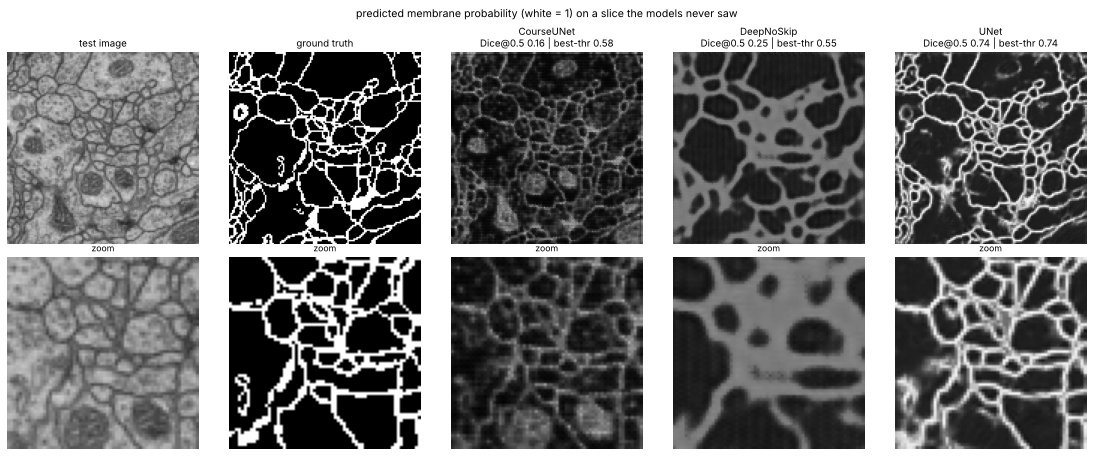

In [9]:
k = 2                                               # one held-out slice
fig, ax = plt.subplots(2, 5, figsize=(16, 6.6), dpi=70)
crop = (slice(30, 94), slice(30, 94))               # 64x64 zoom
panels = [("test image", test_dataset[k][0].permute(1, 2, 0), None), ("ground truth", res["UNet"][3][k, 0], "gray")] + \
         [(f"{n}\nDice@0.5 {res[n][0]:.2f} | best-thr {res[n][5]:.2f}", res[n][2][k, 0], "gray") for n in models]
for j, (title, im, cmap) in enumerate(panels):
    ax[0, j].imshow(im, cmap=cmap, vmin=0, vmax=1); ax[0, j].set_title(title, fontsize=10)
    ax[1, j].imshow(im[crop[0], crop[1]] if im.dim() == 2 else im[crop[0], crop[1], :], cmap=cmap, vmin=0, vmax=1)
    ax[1, j].set_title("zoom", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle("predicted membrane probability (white = 1) on a slice the models never saw", fontsize=11)
plt.tight_layout(); plt.show()

## 3 · Mini project: tumour segmentation prototype

The course asks for a "tumour segmentation prototype". Real tumour datasets (BraTS, LiTS, medical decathlon) are gigabytes in size and need a registration or licence, so to keep the lab self-contained we use **synthetic, MRI-like images**.

> ⚠️ **This data is fake.** Each 128×128 image is a computer-drawn "brain" (a textured ellipse with dark ventricles, blurred and noisy like a scan), and 80 % of them contain one irregular, slightly brighter "tumour" blob of random size, shape and position. It is useful for learning the *pipeline* (data → U-Net → mask → measurements); **nothing learned here says anything about real tumours.** For a real project swap in a real dataset with the same folder layout.

We save it in the same `images/` + `masks/` layout and reuse the **fixed `MedicalDataset` class unchanged**.

synthetic tumour set: train 240 | test 60


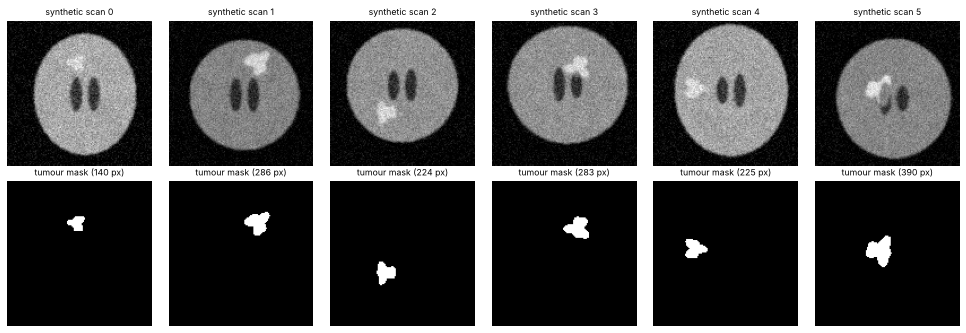

In [10]:
from scipy.ndimage import gaussian_filter

def fake_mri(rng, size=128, p_tumour=0.8):
    yy, xx = np.mgrid[:size, :size] / size
    cx, cy = 0.5 + rng.normal(0, 0.03), 0.5 + rng.normal(0, 0.03)
    ax_, ay_ = rng.uniform(0.33, 0.42), rng.uniform(0.38, 0.46)
    brain = ((xx - cx) / ax_) ** 2 + ((yy - cy) / ay_) ** 2 < 1
    img = np.zeros((size, size)); img[brain] = 0.45
    img += gaussian_filter(rng.normal(0, 1, (size, size)), 3) * 0.08 * brain           # tissue texture
    for sx in (-1, 1):                                                                    # two dark ventricles
        v = ((xx - cx - sx * 0.06) / 0.04) ** 2 + ((yy - cy) / rng.uniform(0.08, 0.12)) ** 2 < 1
        img[v] = 0.15
    mask = np.zeros((size, size), bool)
    if rng.random() < p_tumour:
        r = rng.uniform(0.04, 0.12)
        while True:                                                                       # tumour centre inside the brain
            tx, ty = rng.uniform(0.25, 0.75), rng.uniform(0.2, 0.8)
            if ((tx - cx) / ax_) ** 2 + ((ty - cy) / ay_) ** 2 < 0.5:
                break
        ang = np.arctan2(yy - ty, xx - tx)
        wobble = 1 + 0.25 * np.sin(3 * ang + rng.uniform(0, 6)) + 0.15 * np.sin(5 * ang + rng.uniform(0, 6))
        mask = (np.hypot(xx - tx, yy - ty) < r * wobble) & brain                         # irregular blob
        img[mask] += rng.uniform(0.12, 0.3)                                               # slightly brighter
    img = gaussian_filter(img, 1.0) + rng.normal(0, 0.05, img.shape)                      # scanner blur + noise
    return (np.clip(img, 0, 1) * 255).astype(np.uint8), (mask * 255).astype(np.uint8)

import shutil
troot = os.path.join(DATA, "tumour_synthetic")
shutil.rmtree(troot, ignore_errors=True)                          # regenerate from scratch every run
rng = np.random.default_rng(42)
for split, n in (("train", 240), ("test", 60)):
    for sub in ("images", "masks"):
        os.makedirs(os.path.join(troot, split, sub), exist_ok=True)
    for i in range(n):
        im, mk = fake_mri(rng)
        Image.fromarray(im).save(os.path.join(troot, split, "images", f"{i:03d}.png"))
        Image.fromarray(mk).save(os.path.join(troot, split, "masks", f"{i:03d}.png"))

t_train = MedicalDataset(os.path.join(troot, "train", "images"), os.path.join(troot, "train", "masks"), augment=True)
t_test = MedicalDataset(os.path.join(troot, "test", "images"), os.path.join(troot, "test", "masks"))
print("synthetic tumour set: train", len(t_train), "| test", len(t_test))
fig, ax = plt.subplots(2, 6, figsize=(14, 4.8), dpi=70)
for j in range(6):
    im, mk = t_test[j]
    ax[0, j].imshow(im[0], cmap="gray"); ax[1, j].imshow(mk[0], cmap="gray")
    ax[0, j].set_title(f"synthetic scan {j}", fontsize=9); ax[1, j].set_title(f"tumour mask ({int(mk.sum())} px)", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [11]:
train_loader = DataLoader(t_train, batch_size=16, shuffle=True)        # train() above uses the global train_loader
t_test_loader = DataLoader(t_test, batch_size=60, shuffle=False)

torch.manual_seed(0); random.seed(0)
tumour_model = UNet()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(tumour_model.parameters(), lr=0.001)
t0 = time.time()
tumour_hist = []
for epoch in range(1, 9):
    tumour_model.train(); running = 0.0
    for images, masks in train_loader:
        optimizer.zero_grad()
        loss = criterion(tumour_model(images), masks)
        loss.backward(); optimizer.step(); running += loss.item()
    d, i, _, _ = evaluate(tumour_model, t_test_loader)
    tumour_hist.append((running / len(train_loader), d))
    print(f"Epoch {epoch:2d}, Loss: {running/len(train_loader):.4f}, test Dice: {d:.3f}")
print(f"trained in {time.time()-t0:.0f} s")

Epoch  1, Loss: 0.7090, test Dice: 0.000


Epoch  2, Loss: 0.5722, test Dice: 0.000


Epoch  3, Loss: 0.5220, test Dice: 0.761


Epoch  4, Loss: 0.4887, test Dice: 0.818


Epoch  5, Loss: 0.4631, test Dice: 0.842


Epoch  6, Loss: 0.4387, test Dice: 0.845


Epoch  7, Loss: 0.4139, test Dice: 0.861


Epoch  8, Loss: 0.3894, test Dice: 0.861
trained in 37 s


pixel-level on 60 held-out synthetic scans: Dice 0.861, IoU 0.756
scan-level 'is there a tumour?': 51 TP, 8 TN, 0 FP, 1 FN  -> accuracy 98%
tumour area error on scans with a tumour: median 11.3%, 90th percentile 32.3%


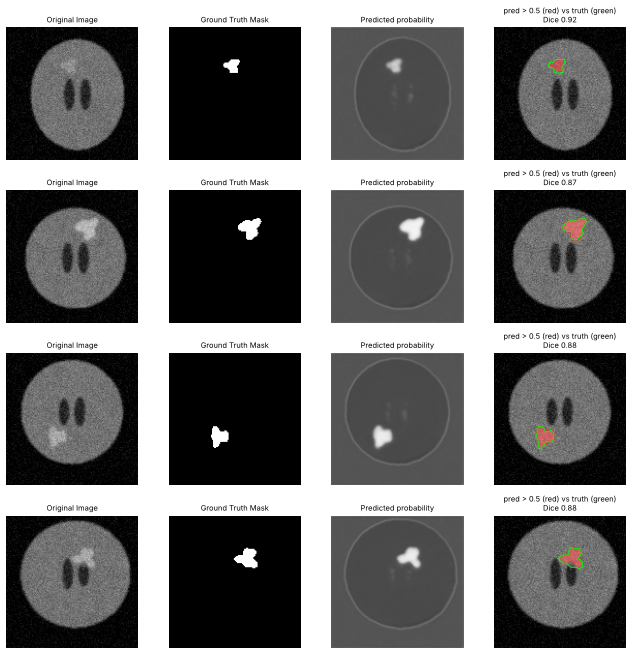

In [12]:
# The course's visualisation, done on the TEST set, in eval mode, with a 0.5 threshold, plus per-scan numbers
d, i, logits, targets = evaluate(tumour_model, t_test_loader)
preds = torch.sigmoid(logits)
binary = (preds > 0.5).float()
print(f"pixel-level on {len(t_test)} held-out synthetic scans: Dice {d:.3f}, IoU {i:.3f}")

true_area = targets.sum((1, 2, 3)); pred_area = binary.sum((1, 2, 3))
has_t, said_t = true_area > 0, pred_area > 20                     # "tumour present" if > 20 predicted pixels
tp = int((has_t & said_t).sum()); tn = int((~has_t & ~said_t).sum())
fp = int((~has_t & said_t).sum()); fn = int((has_t & ~said_t).sum())
print(f"scan-level 'is there a tumour?': {tp} TP, {tn} TN, {fp} FP, {fn} FN  -> accuracy {(tp+tn)/len(t_test):.0%}")
rel = ((pred_area - true_area).abs() / true_area.clamp(min=1))[has_t]
print(f"tumour area error on scans with a tumour: median {rel.median():.1%}, 90th percentile {rel.quantile(0.9):.1%}")

fig, axs = plt.subplots(4, 4, figsize=(11, 11), dpi=60)
for row, k in enumerate([0, 1, 2, 3]):
    per = dice_iou(logits[k:k+1], targets[k:k+1])[0] if targets[k].sum() > 0 else float("nan")
    axs[row, 0].imshow(t_test[k][0].permute(1, 2, 0)); axs[row, 0].set_title('Original Image', fontsize=9)
    axs[row, 1].imshow(targets[k][0], cmap='gray'); axs[row, 1].set_title('Ground Truth Mask', fontsize=9)
    axs[row, 2].imshow(preds[k][0], cmap='gray', vmin=0, vmax=1); axs[row, 2].set_title('Predicted probability', fontsize=9)
    over = t_test[k][0].permute(1, 2, 0).numpy().copy()
    over[binary[k, 0].bool().numpy()] = 0.6 * over[binary[k, 0].bool().numpy()] + 0.4 * np.array([1, 0, 0])
    axs[row, 3].imshow(over); axs[row, 3].contour(targets[k][0], levels=[0.5], colors="lime", linewidths=1)
    axs[row, 3].set_title(f"pred > 0.5 (red) vs truth (green)\nDice {per:.2f}", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 🔧 What we changed from the course notebook, and why

| Course code | Problem | Fix here |
|---|---|---|
| `./medical/train/images` placeholder | no data | ISBI-2012 EM membrane slices (the U-Net paper's dataset), arranged in the course's folder layout, 24 train / 6 test |
| `mask = self.transform(mask)` with `Resize((128,128))` | bilinear resize creates **non-binary mask values** on every edge | separate mask transform: `InterpolationMode.NEAREST` + `> 0.5` |
| `os.listdir(...)` | arbitrary file order | `sorted(...)` |
| no augmentation | 24 images is very little data | random flips/90° rotations applied **identically** to image and mask |
| `class UNet` = 1 conv + pool + 1 transposed conv | **not a U-Net**: no skip connections, one level, 4×4-pixel view | kept as `CourseUNet` for comparison; added a real 4-level `UNet` with skip connections, plus `DeepNoSkip` to isolate the skips' effect |
| 2 epochs | 12 weight updates, far from converged | 40 epochs, with the curve shown |
| evaluation with `next(iter(train_loader))` | judges the model on images it trained on | separate **test** split; Dice/IoU on it |
| no `model.eval()` / `torch.no_grad()` | BatchNorm would use batch statistics; gradients tracked for nothing | both added in `evaluate()` |
| shows `sigmoid` output only | a probability map isn't a mask | also `> 0.5`, overlays, Dice per scan, tumour-present accuracy and area error |
| "tumour" prototype on the same data | no tumour data | clearly labelled **synthetic** MRI-like tumour set |

## Results, honestly

Measured in the run above: 24 training and **6 held-out** EM slices at 128×128, 40 epochs each, same loss, optimiser and augmentation for all three models.

| Model | Parameters | Dice @ 0.5 | IoU @ 0.5 | Best-threshold Dice | Boundary F1 | Contrast |
|---|---|---|---|---|---|---|
| course "U-Net" (1 level, no skips) | 10,049 | 0.160 | 0.087 | 0.583 (thr 0.25) | 0.838 | 0.171 |
| DeepNoSkip (4 levels, no skips) | 109,433 | 0.249 | 0.142 | 0.549 (thr 0.35) | 0.675 | 0.188 |
| **real U-Net (4 levels + skips)** | 121,529 | **0.736** | **0.582** | 0.736 (thr 0.50) | **0.932** | **0.469** |
| zero-skill "everything is membrane" | – | 0.329 | 0.197 | – | 0.119 | 0 |

What this shows:
- **At the standard 0.5 threshold, both models without skip connections score *below* the zero-skill reference** (0.160 and 0.249 vs 0.329). They are **under-confident**: their membrane probabilities rarely pass 0.5. Their best-threshold Dice (0.58 and 0.55) shows they pick up some structure, but their low contrast (≈ 0.17–0.19) means they barely separate membrane from background.
- **The real U-Net is the only model that clearly works**: Dice 0.736 at the normal threshold, more than twice the contrast, and the sharpest outlines (boundary F1 0.932).
- **Depth alone did not help.** DeepNoSkip has almost as many parameters as the U-Net and sees much more context, yet it did no better than the tiny course model, and its outlines were *blurrier* (boundary F1 0.675 vs 0.838). Its test Dice also jumped around during training (0.33 → 0.00 → 0.25). What made the difference is the **skip connections**, which carry the fine detail lost by pooling straight to the decoder. That's the point of the U-Net design.
- **The course model learned slowly:** its test Dice was 0.000 for the first 20 epochs. The course's 2 epochs (12 weight updates) would show nothing at all.
- **Tumour prototype (synthetic data):** Dice **0.861**, IoU 0.756 on 60 held-out fake scans. Asked "is there a tumour?", it was right on 59 of 60 (51 found, 8 correctly empty, 0 false alarms, 1 missed). The estimated tumour area was off by a median of 11.3% (90th percentile 32.3%). **Synthetic data says nothing about real tumours**; it only shows the pipeline works.
- **Caveats:** 6 test slices is very few, so treat the numbers as a ranking, not precise values. Picking the best threshold on the test set flatters the first two models slightly (a real project would choose it on validation data). CPU timings were on a shared machine.

## Common errors and how to fix them

| Error | Cause | Fix |
|---|---|---|
| `ValueError: Target size (torch.Size([4, 1, 128, 128])) must be the same as input size (...)` | output and mask sizes differ (e.g. odd input size with pooling) | use sizes divisible by 2^(number of pools), e.g. 128, 256 |
| `RuntimeError: Sizes of tensors must match except in dimension 1` in `torch.cat` | skip and upsampled maps differ by a pixel | same: input divisible by 16 for 4 levels (or crop/pad before `cat`) |
| loss goes down but mask is all black | heavy class imbalance (few foreground pixels) | train longer, use Dice loss or `pos_weight` in `BCEWithLogitsLoss` |
| mask looks "fuzzy" / has values like 0.3 | bilinear resize of the mask | nearest-neighbour + threshold |
| `FileNotFoundError` for a mask | image and mask file names differ | the loader assumes identical names in both folders |
| image and mask don't line up after augmentation | two independent random transforms | apply the same random op to both inside `__getitem__` |
| very different test results each run | BatchNorm in train mode during evaluation | `model.eval()` before predicting |

## Try this yourself

1. Change `EPOCHS = 40` to 15: how much worse is each model? (Look at the Dice curve first.)
2. Remove `augment=True` from the membrane training set. Does the gap between train loss and test Dice grow?
3. Train at 256×256 instead of 128 (`MedicalDataset(..., size=256)`): membranes are thicker in pixels; does Dice improve? (About 4× slower.)
4. Change the threshold 0.5 to 0.3 and 0.7 inside `dice_iou`. Which threshold gives the best Dice for the membrane task?
5. Replace `BCEWithLogitsLoss` with BCE + Dice loss: `loss = bce + (1 - soft_dice)` where `soft_dice` uses `sigmoid(outputs)` directly.

## Run it on Google Colab with a GPU

1. Upload the notebook, *Runtime → Change runtime type → T4 GPU*.
2. Everything it needs (`torch`, `torchvision`, `scipy`, `PIL`) is preinstalled; the data downloads from GitHub.
3. *Run all*. `device` prints `cuda`; on a GPU you can afford `EPOCHS = 200`, `UNet(base=32)` and `size=256`.

## Viva questions

1. **What is semantic segmentation?** Assigning a class to every pixel; the output is a mask the size of the image.
2. **Why is the course's `UNet` not a real U-Net?** It has one down/up level and no skip connections; a U-Net has several levels and concatenates encoder features into the decoder at each level.
3. **What do skip connections give U-Net?** The decoder gets the encoder's high-resolution features directly, so it can place boundaries precisely instead of guessing them from a coarse map.
4. **What does `ConvTranspose2d(64, 32, 2, stride=2)` do?** Learned upsampling: doubles height and width, turns 64 channels into 32.
5. **What does the final `Conv2d(32, 1, 1)` do?** A 1×1 convolution that combines the channels into one logit per pixel.
6. **Why `BCEWithLogitsLoss` rather than `Sigmoid` + `BCELoss`?** It combines both in a numerically stable way; the model outputs raw logits.
7. **How do you turn the output into a mask?** `torch.sigmoid(logits) > 0.5`.
8. **Define Dice and IoU.** Dice = 2|A∩B| / (|A|+|B|); IoU = |A∩B| / |A∪B|; Dice = 2·IoU/(1+IoU), so Dice ≥ IoU.
9. **Why not pixel accuracy?** With 22 % membrane (or 1 % tumour), predicting "all background" already scores 78 % (or 99 %) accuracy; Dice/IoU focus on the foreground.
10. **Why resize masks with nearest-neighbour?** Bilinear interpolation averages labels and creates values that are not valid classes.
11. **Why `model.eval()` at test time?** BatchNorm switches to its stored running statistics (and dropout turns off), so predictions don't depend on the batch.
12. **Why is U-Net popular in medicine?** It works with very little training data (heavy augmentation + skip connections) and gives precise boundaries, which matter for measuring organs and tumours.
13. **Why did we hold out test slices?** A model can memorise training images; only unseen images show whether it generalises.
14. **What did the `DeepNoSkip` experiment show?** See "Results, honestly": it separates the benefit of depth (context) from the benefit of skip connections (detail).